<a href="https://colab.research.google.com/github/Maanvijangir/Stock_market_forecasting/blob/main/Stock_predict.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install yfinance

In [ ]:
import yfinance as yf
import pandas as pd
import sqlite3

In [ ]:
stocks = [
    "TCS.NS",
    "INFY.NS",
    "RELIANCE.NS",
    "HDFCBANK.NS",
    "JIOFIN.NS"
]

all_data = []

In [ ]:
df = yf.download("TCS.NS", start="2020-01-01", end="2025-01-01")

print(df.head())
print(df.columns)

/tmp/ipykernel_1052/2161559993.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download("TCS.NS", start="2020-01-01", end="2025-01-01")
[*********************100%***********************]  1 of 1 completed

Price             Close         High          Low         Open   Volume
Ticker           TCS.NS       TCS.NS       TCS.NS       TCS.NS   TCS.NS
Date                                                                   
2020-01-01  1821.427002  1835.123672  1809.998886  1821.763039  1354908
2020-01-02  1813.066040  1831.804697  1805.965574  1831.804697  2380752
2020-01-03  1849.198242  1867.978949  1818.401460  1818.401460  4655761
2020-01-06  1849.030273  1870.457833  1838.484512  1852.853663  3023209
2020-01-07  1853.568604  1860.963051  1835.040020  1849.072934  2429317
MultiIndex([( 'Close', 'TCS.NS'),
            (  'High', 'TCS.NS'),
            (   'Low', 'TCS.NS'),
            (  'Open', 'TCS.NS'),
            ('Volume', 'TCS.NS')],
           names=['Price', 'Ticker'])


In [ ]:
for stock in stocks:

  df = yf.download(
      stock,
      start="2021-01-01",
      end="2026-01-01"
  )

  df.columns = df.columns.get_level_values(0)

  df.reset_index(inplace=True)

  df["Ticker"] = stock

  # df = df[
  #       [
  #           "Date",
  #           "Open",
  #           "High",
  #           "Low",
  #           "Close",
  #           "Volume",
  #           "Ticker"
  #       ]
  #   ]

  all_data.append(df)

combined_df = pd.concat(all_data, ignore_index=True)

combined_df.head()

/tmp/ipykernel_1052/377712044.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1052/377712044.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1052/377712044.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1052/377712044.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(
[*********************100%***********************]  1 of 1 completed
/tmp/ipykernel_1052/377712044.py:3: FutureWarning: YF.download() has changed argument auto_adjust default to True
  df = yf.download(
[*********************100%***********************]  1 

Price,Date,Close,High,Low,Open,Volume,Ticker
0,2021-01-01,2507.742676,2517.805333,2465.565154,2466.421551,2681440,TCS.NS
1,2021-01-04,2602.974121,2612.651443,2518.619072,2526.369501,5113293,TCS.NS
2,2021-01-05,2648.834229,2667.032653,2603.102742,2603.102742,5801309,TCS.NS
3,2021-01-06,2613.293945,2666.390529,2601.047433,2654.829176,3726716,TCS.NS
4,2021-01-07,2597.278809,2638.428694,2569.403066,2633.418692,3717827,TCS.NS


In [ ]:
print(combined_df.columns)

Index(['Date', 'Close', 'High', 'Low', 'Open', 'Volume', 'Ticker'], dtype='object', name='Price')


Save to SQL

In [ ]:
#Save to sql
conn = sqlite3.connect("stck_data.db")

combined_df.to_sql(
    "stock_prices",
    conn,
    if_exists="replace",
    index=False
)

5528

In [ ]:
pd.read_sql(
    "SELECT * FROM stock_prices LIMIT 15",
    conn
)

,Date,Close,High,Low,Open,Volume,Ticker
0,2021-01-01 00:00:00,2507.742676,2517.805333,2465.565154,2466.421551,2681440,TCS.NS
1,2021-01-04 00:00:00,2602.974121,2612.651443,2518.619072,2526.369501,5113293,TCS.NS
2,2021-01-05 00:00:00,2648.834229,2667.032653,2603.102742,2603.102742,5801309,TCS.NS
3,2021-01-06 00:00:00,2613.293945,2666.390529,2601.047433,2654.829176,3726716,TCS.NS
4,2021-01-07 00:00:00,2597.278809,2638.428694,2569.403066,2633.418692,3717827,TCS.NS
5,2021-01-08 00:00:00,2672.728027,2678.808527,2620.573559,2646.265456,5879039,TCS.NS
6,2021-01-11 00:00:00,2720.300537,2766.160610,2694.694366,2766.160610,9508039,TCS.NS
7,2021-01-12 00:00:00,2718.930908,2749.033166,2697.649368,2720.301017,3611458,TCS.NS
8,2021-01-13 00:00:00,2705.313721,2720.771720,2677.309597,2719.058927,3572801,TCS.NS
9,2021-01-14 00:00:00,2789.185303,2802.742157,2677.384464,2707.072250,6931542,TCS.NS


In [ ]:
#Total records
pd.read_sql("""
SELECT COUNT(*) AS Total_Records FROM stock_prices""", conn)

,Total_Records
0,5528


In [ ]:
#Stocks available
pd.read_sql(""" SELECT DISTINCT Ticker FROM stock_prices""",conn)

,Ticker
0,TCS.NS
1,INFY.NS
2,RELIANCE.NS
3,HDFCBANK.NS
4,JIOFIN.NS


In [ ]:
#Records per stock
pd.read_sql(""" SELECT Ticker, COUNT(*) AS Records FROM stock_prices GROUP BY Ticker""",conn)

,Ticker,Records
0,HDFCBANK.NS,1236
1,INFY.NS,1236
2,JIOFIN.NS,584
3,RELIANCE.NS,1236
4,TCS.NS,1236


In [ ]:
combined_df.shape

(5528, 7)

In [ ]:
combined_df.isnull().sum()

,0
Price,
Date,0
Close,0
High,0
Low,0
Open,0
Volume,0
Ticker,0


In [ ]:
combined_df.describe()

Price,Date,Close,High,Low,Open,Volume
count,5528,5528.000000,5528.000000,5528.000000,5528.000000,5.528000e+03
mean,2023-08-22 14:02:57.134587648,1506.519400,1520.444942,1493.116938,1506.979238,1.315785e+07
min,2021-01-01 00:00:00,200.138474,207.230771,197.877299,199.212096,0.000000e+00
25%,2022-05-26 00:00:00,788.303711,793.872394,782.744986,789.391759,4.260615e+06
50%,2023-10-05 00:00:00,1240.695618,1253.202431,1229.247754,1242.590537,9.053218e+06
75%,2024-11-21 00:00:00,1684.423126,1698.814904,1664.837141,1688.388066,1.620770e+07
max,2025-12-31 00:00:00,4208.337891,4243.917580,4169.754807,4228.900265,4.453421e+08
std,NaN,986.015541,994.867313,977.618543,986.348165,1.721069e+07


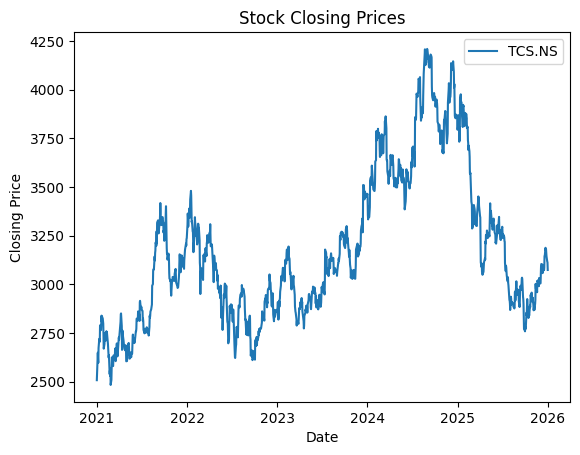

<Figure size 2500x600 with 0 Axes>

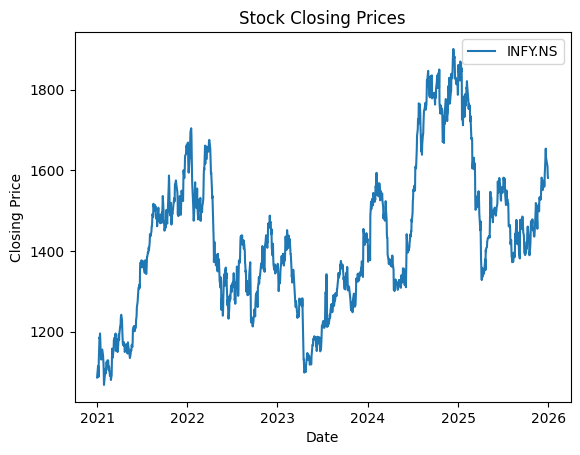

<Figure size 2500x600 with 0 Axes>

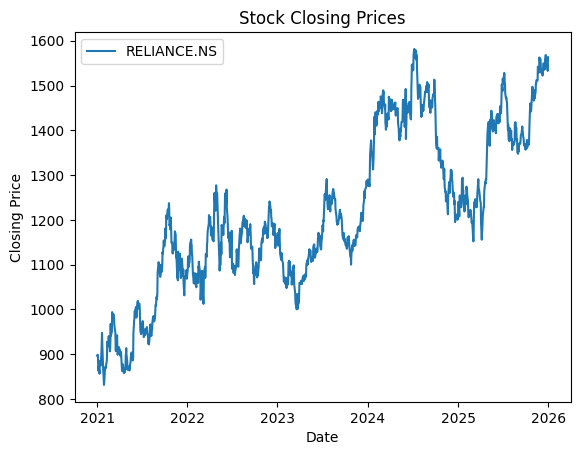

<Figure size 2500x600 with 0 Axes>

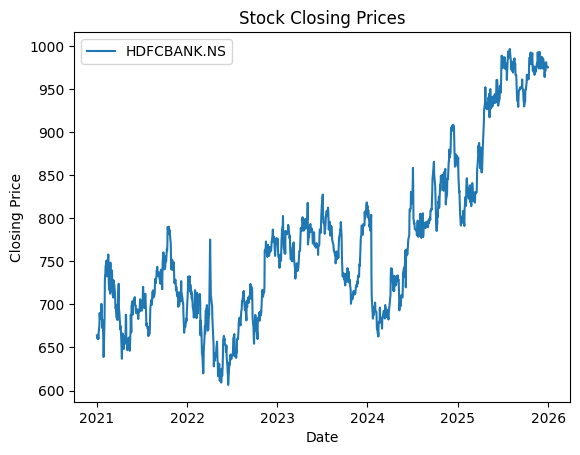

<Figure size 2500x600 with 0 Axes>

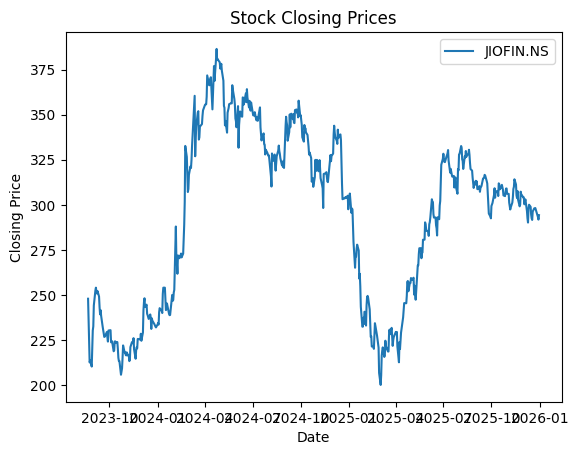

<Figure size 2500x600 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt

for stock in combined_df["Ticker"].unique():
  temp = combined_df[
      combined_df["Ticker"]==stock
  ]
  plt.plot(
      temp["Date"],
      temp["Close"],
      label=stock
  )
  plt.legend()
  plt.title("Stock Closing Prices")
  plt.xlabel("Date")
  plt.ylabel("Closing Price")
  plt.figure(figsize=(25,6))
  plt.show()


In [ ]:
#Load TCS Data
df = pd.read_sql(""" SELECT * FROM stock_prices WHERE Ticker='TCS.NS' ORDER BY Date""",conn)

In [ ]:
data=df[["Close"]]
data.head()

,Close
0,2507.742676
1,2602.974121
2,2648.834229
3,2613.293945
4,2597.278809


In [ ]:
#Scale Data
#LSTMs work better when values are between 0 and 1
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
scaled_data = scaler.fit_transform(data)
scaled_data[:5]
#It creates sequence; Use previous 60 days to predict the next day.

array([[0.01412049],
       [0.06932865],
       [0.09591495],
       [0.07531132],
       [0.06602693]])

In [ ]:
sequence_length = 60
x = []
y = []

for i in range(sequence_length, len(scaled_data)):
  x.append(scaled_data[i-sequence_length:i, 0])
  y.append(scaled_data[i, 0])


In [ ]:
print(y[:5])
print(y.min())
print(y.max())

[np.float64(0.1410431532233467), np.float64(0.1346513044899762), np.float64(0.17141069761747563), np.float64(0.18424407376505658), np.float64(0.18757693295713396)]


AttributeError: 'list' object has no attribute 'min'

In [ ]:
import numpy as np

x = np.array(x)
y = np.array(y)

In [ ]:
print(x.shape)
print(y.shape)

(1176, 60)
(1176,)


In [ ]:
x = x.reshape(
    x.shape[0],
    x.shape[1],
    1
)
print(x.shape)

(1176, 60, 1)


In [ ]:
split = int(len(x)*0.8)
x_train = x[:split]
x_test = x[split:]
y_train = y[:split]
y_test = y[split:]
print(x_train.shape)
print(x_test.shape)
#940 training samples; 60 previous days; 1 feature
#y_train[0] contains Day 61 close

(940, 60, 1)
(236, 60, 1)


In [ ]:
import torch
X_train = torch.FloatTensor(x_train)
X_test = torch.FloatTensor(x_test)
y_train = torch.FloatTensor(y_train)
y_test = torch.FloatTensor(y_test)


In [ ]:
y_train = y_train.reshape(-1, 1)
y_test = y_test.reshape(-1, 1)

In [ ]:
print(X_train.shape)
print(y_train.shape)


torch.Size([940, 60, 1])
torch.Size([940, 1])


In [ ]:
#Build First LSTM
import torch.nn as nn
class StockLSTM(nn.Module):
  def __init__(self):
    super().__init__()

    self.lstm = nn.LSTM(
        input_size=1,
        hidden_size=50,
        num_layers = 2,
        batch_first = True
    )
    self.fc = nn.Linear(
        50,1
    )
  def forward(self,x):
   out, _ = self.lstm(x)
   out = out[:,-1,:]
   out = self.fc(out)
   return out

In [ ]:
print(y_train[:5])

tensor([[0.1410],
        [0.1347],
        [0.1714],
        [0.1842],
        [0.1876]])


In [ ]:
for name, param in model.named_parameters():
    print(name, param.data.abs().max())

NameError: name 'model' is not defined

In [ ]:
model = StockLSTM()

with torch.no_grad():
    print(model(X_train[:5]))

tensor([[0.0546],
        [0.0547],
        [0.0547],
        [0.0547],
        [0.0548]])


In [ ]:
model = StockLSTM()
print(model)

StockLSTM(
  (lstm): LSTM(1, 50, num_layers=2, batch_first=True)
  (fc): Linear(in_features=50, out_features=1, bias=True)
)


In [ ]:
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(), lr=0.001
)

In [ ]:
epochs = 50
for epoch in range(epochs):
  outputs = model(X_train)
  loss = criterion(
      outputs,
      y_train
  )
  optimizer.zero_grad()
  loss.backward()

  optimizer.step()
  if epoch % 5 == 0:
    print(f"Epoch {epoch}, Loss: {loss.item():.6f}")

Epoch 0, Loss: 0.152893
Epoch 5, Loss: 0.098299
Epoch 10, Loss: 0.055198
Epoch 15, Loss: 0.054921
Epoch 20, Loss: 0.044904
Epoch 25, Loss: 0.041363
Epoch 30, Loss: 0.036573
Epoch 35, Loss: 0.025995
Epoch 40, Loss: 0.015439
Epoch 45, Loss: 0.008706


In [ ]:
model.eval()
with torch.no_grad():
  predictions = model(X_test)

print(predictions[:5])
print(predictions.min())
print(predictions.max())
predictions = predictions.numpy()
actual = y_test.numpy()

tensor([[0.8660],
        [0.8651],
        [0.8627],
        [0.8618],
        [0.8616]])
tensor(0.2351)
tensor(0.8660)


In [ ]:
print(predictions[:5])
print(actual[:5])


[[0.8659896 ]
 [0.8651244 ]
 [0.86265177]
 [0.86180705]
 [0.8615933 ]]
[[0.79063606]
 [0.76769185]
 [0.83373535]
 [0.82763666]
 [0.8314105 ]]


In [ ]:
predictions_real = scaler.inverse_transform(predictions.reshape(-1,1))
actual_real = scaler.inverse_transform(actual.reshape(-1,1))

print("Predicted:",predictions_real[:5])
print("Actual:",actual_real[:5])

Predicted: [[3977.1763]
 [3975.6838]
 [3971.4187]
 [3969.9617]
 [3969.593 ]]
Actual: [[3847.195 ]
 [3807.6172]
 [3921.5393]
 [3911.0193]
 [3917.529 ]]


Evaluate the model


In [ ]:
from sklearn.metrics import mean_squared_error
import numpy as np

rmse = np.sqrt(
    mean_squared_error(actual_real,predictions_real)
)
print("RMSE:",rmse)

RMSE: 130.07168246057634


In [ ]:
from sklearn.metrics import mean_absolute_error

mae = mean_absolute_error(
    actual_real,predictions_real
)
print("MAE:",mae)

MAE: 105.63074493408203


In [ ]:
from sklearn.metrics import r2_score

r2 = r2_score(
    actual_real,
    predictions_real
)

print("R2 Score:", r2)

R2 Score: 0.776724636554718


Interpretation:

MAE = 93.65
```
This means prediction is off by about 94rs on avg.
For a stock trading around 3000-4000
```
94/3200 ~ 2.9%


---
RMSE = 113
```
it penalizes larger error more heavily.
Sinece it is only slightly higher than MAE; it indicates we don't have many huge prediction misses.
```


---
r^2 = 0.83
```
means roughly 83% of the variation in the testing data is being explained by the model.
Below 0.5 ➡ weak
0.5 - 0.7 ➡ decent
0.7 - 0.8 ➡ good
Above 0.8 ➡ very good
```


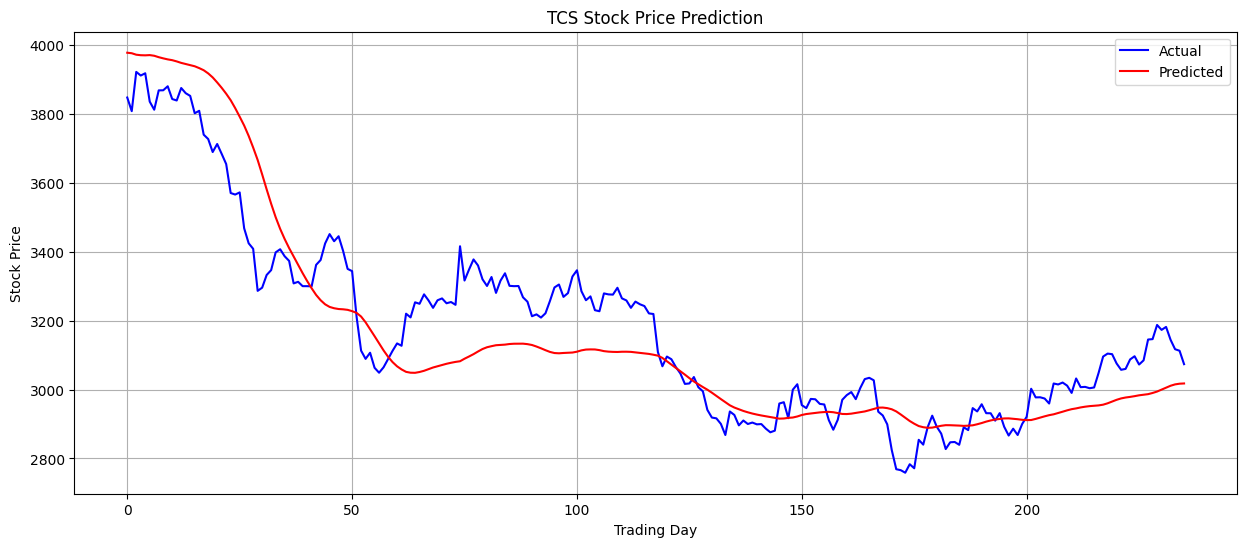

In [ ]:
import matplotlib.pyplot as plt
plt.figure(figsize=(15,6))
plt.plot(actual_real,label="Actual",color="blue")
plt.plot(predictions_real, label="Predicted",color="red")
plt.title("TCS Stock Price Prediction")
plt.xlabel("Trading Day")
plt.ylabel("Stock Price")
plt.legend()
plt.grid(True)
plt.show()

## NOW WORK WITH MULTISTOCKS


In [ ]:
import torch
import torch.nn as nn

class StockLSTM(nn.Module):

    def __init__(self):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=1,
            hidden_size=50,
            num_layers=2,
            batch_first=True
        )

        self.fc = nn.Linear(50, 1)

    def forward(self, x):

        out, _ = self.lstm(x)

        out = out[:, -1, :]

        out = self.fc(out)

        return out


In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import r2_score

import numpy as np
import torch


def train_stock(df, ticker):

    print(f"\nTraining {ticker}")

    stock_df = df[df["Ticker"] == ticker].copy()

    data = stock_df[["Close"]]

    scaler = MinMaxScaler()

    scaled_data = scaler.fit_transform(data)

    sequence_length = 60

    X = []
    y = []

    for i in range(sequence_length, len(scaled_data)):

        X.append(
            scaled_data[
                i-sequence_length:i,
                0
            ]
        )

        y.append(
            scaled_data[
                i,
                0
            ]
        )

    X = np.array(X)
    y = np.array(y)

    X = X.reshape(
        X.shape[0],
        X.shape[1],
        1
    )

    split = int(len(X) * 0.8)

    X_train = X[:split]
    X_test = X[split:]

    y_train = y[:split]
    y_test = y[split:]

    X_train = torch.FloatTensor(X_train)
    X_test = torch.FloatTensor(X_test)

    y_train = torch.FloatTensor(
        y_train.reshape(-1,1)
    )

    y_test = torch.FloatTensor(
        y_test.reshape(-1,1)
    )

    model = StockLSTM()

    criterion = nn.MSELoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    epochs = 150

    for epoch in range(epochs):

        outputs = model(X_train)

        loss = criterion(
            outputs,
            y_train
        )

        optimizer.zero_grad()

        loss.backward()

        optimizer.step()

    model.eval()

    with torch.no_grad():

        predictions = model(X_test)

    predictions = predictions.numpy()

    actual = y_test.numpy()

    predictions_real = scaler.inverse_transform(
        predictions.reshape(-1,1)
    )

    actual_real = scaler.inverse_transform(
        actual.reshape(-1,1)
    )

    rmse = np.sqrt(
        mean_squared_error(
            actual_real,
            predictions_real
        )
    )

    mae = mean_absolute_error(
        actual_real,
        predictions_real
    )

    r2 = r2_score(
        actual_real,
        predictions_real
    )

    print(f"RMSE : {rmse:.2f}")
    print(f"MAE  : {mae:.2f}")
    print(f"R²   : {r2:.4f}")

    return {
        "ticker": ticker,
        "model" : model,
        "actual": actual,
        "predictions": predictions,
        "rmse": rmse,
        "mae": mae,
        "r2": r2
    }

In [ ]:
stocks = [
    "TCS.NS",
    "INFY.NS",
    "RELIANCE.NS",
    "HDFCBANK.NS",
    "JIOFIN.NS"
]

results = []

for stock in stocks:

    result = train_stock(
        combined_df,
        stock
    )

    results.append(result)


Training TCS.NS
RMSE : 92.58
MAE  : 69.68
R²   : 0.8869

Training INFY.NS
RMSE : 49.85
MAE  : 39.19
R²   : 0.8002

Training RELIANCE.NS
RMSE : 38.93
MAE  : 29.58
R²   : 0.8722

Training HDFCBANK.NS
RMSE : 29.91
MAE  : 26.45
R²   : 0.7377

Training JIOFIN.NS
RMSE : 6.33
MAE  : 5.04
R²   : 0.6202


In [ ]:
import joblib
from sklearn.preprocessing import MinMaxScaler

stocks = [
    "TCS.NS",
    "INFY.NS",
    "RELIANCE.NS",
    "HDFCBANK.NS",
    "JIOFIN.NS"
]

for stock in stocks:

    stock_df = combined_df[
        combined_df["Ticker"] == stock
    ]

    scaler = MinMaxScaler()

    scaler.fit(
        stock_df[["Close"]]
    )

    joblib.dump(
        scaler,
        f"{stock}_scaler.pkl"
    )

print("All scalers saved.")

All scalers saved.


In [ ]:
for result in results:

    torch.save(
        result["model"].state_dict(),
        f"{result['ticker']}_LSTM.pth"
    )

In [ ]:
import pandas as pd

results_df = pd.DataFrame(results)

results_df


,ticker,model,rmse,mae,r2
0,TCS.NS,"StockLSTM(\n (lstm): LSTM(1, 50, num_layers=2...",86.970875,65.482140,0.900179
1,INFY.NS,"StockLSTM(\n (lstm): LSTM(1, 50, num_layers=2...",47.559148,37.295368,0.818103
2,RELIANCE.NS,"StockLSTM(\n (lstm): LSTM(1, 50, num_layers=2...",37.451518,29.532364,0.881730
3,HDFCBANK.NS,"StockLSTM(\n (lstm): LSTM(1, 50, num_layers=2...",24.750963,21.495663,0.820335
4,JIOFIN.NS,"StockLSTM(\n (lstm): LSTM(1, 50, num_layers=2...",6.743717,5.139708,0.568327


In [ ]:
import matplotlib.pyplot as plt

def plot_from_results(result):

    plt.figure(figsize=(15,6))

    plt.plot(
        result["actual"],
        label="Actual",
        color="blue"
    )

    plt.plot(
        result["predictions"],
        label="Predicted",
        color="red"
    )

    plt.title(
        f'{result["ticker"]} | '
        f'R²={result["r2"]:.3f} | '
        f'MAE={result["mae"]:.2f}'
    )

    plt.xlabel("Trading Days")
    plt.ylabel("Price (₹)")
    plt.legend()
    plt.grid(True)

    plt.show()

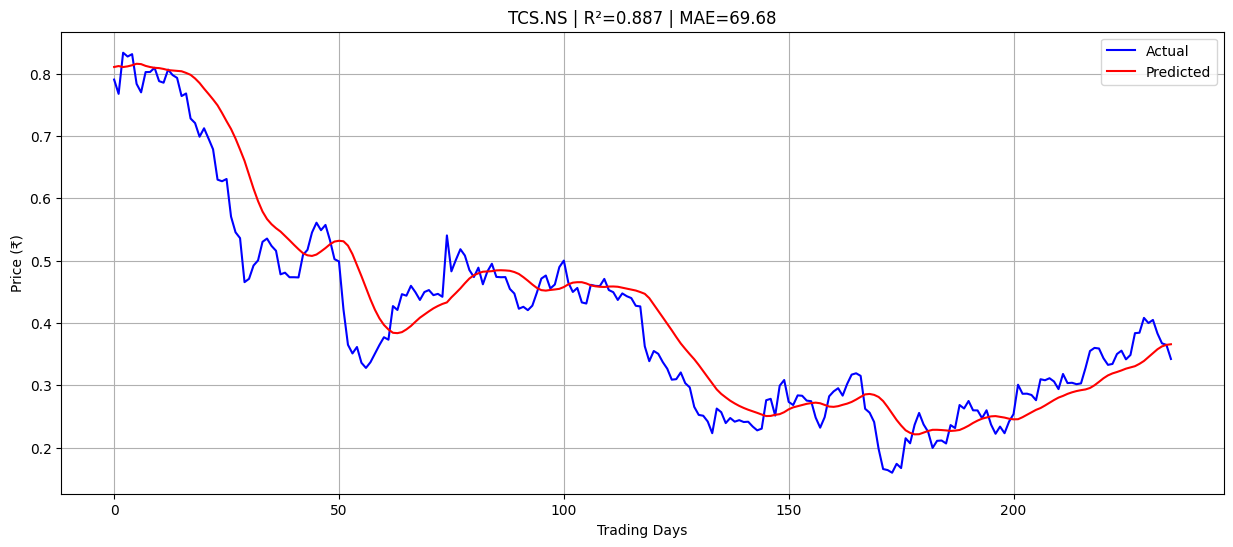

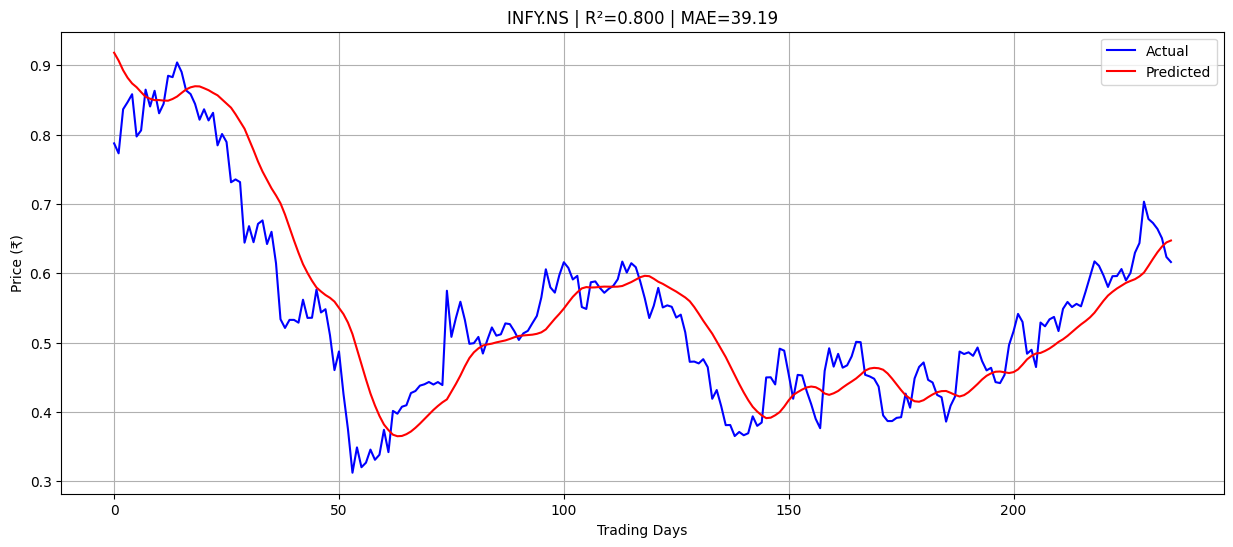

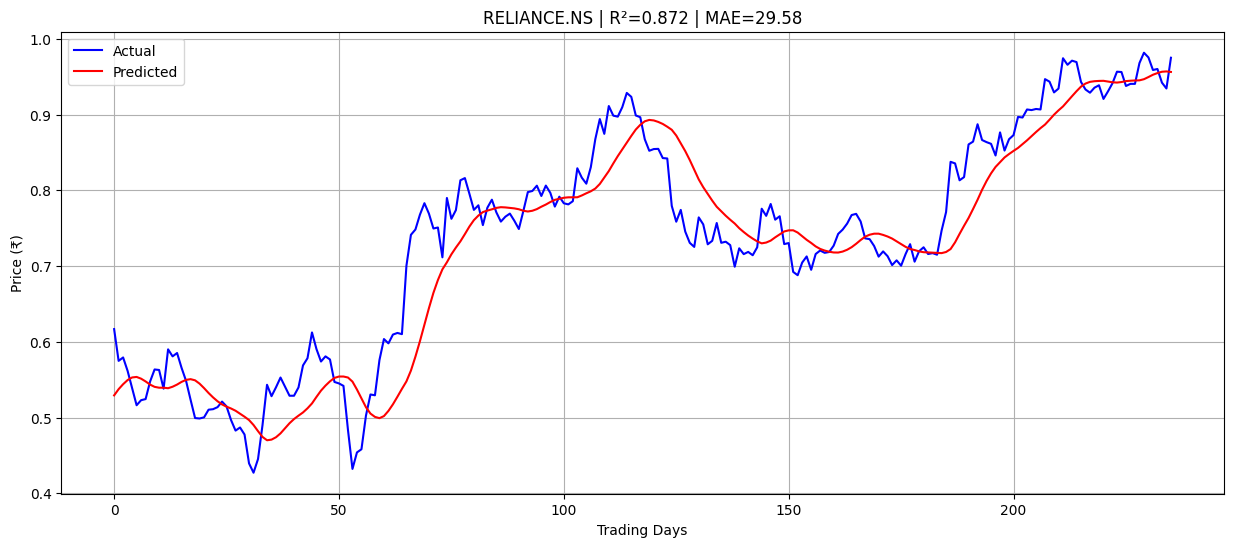

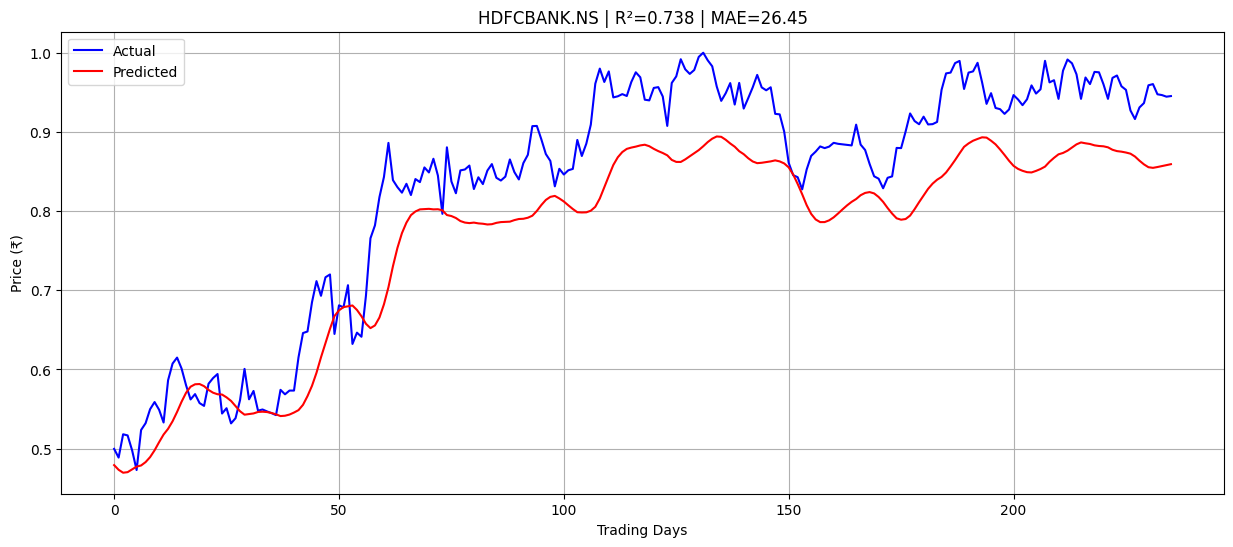

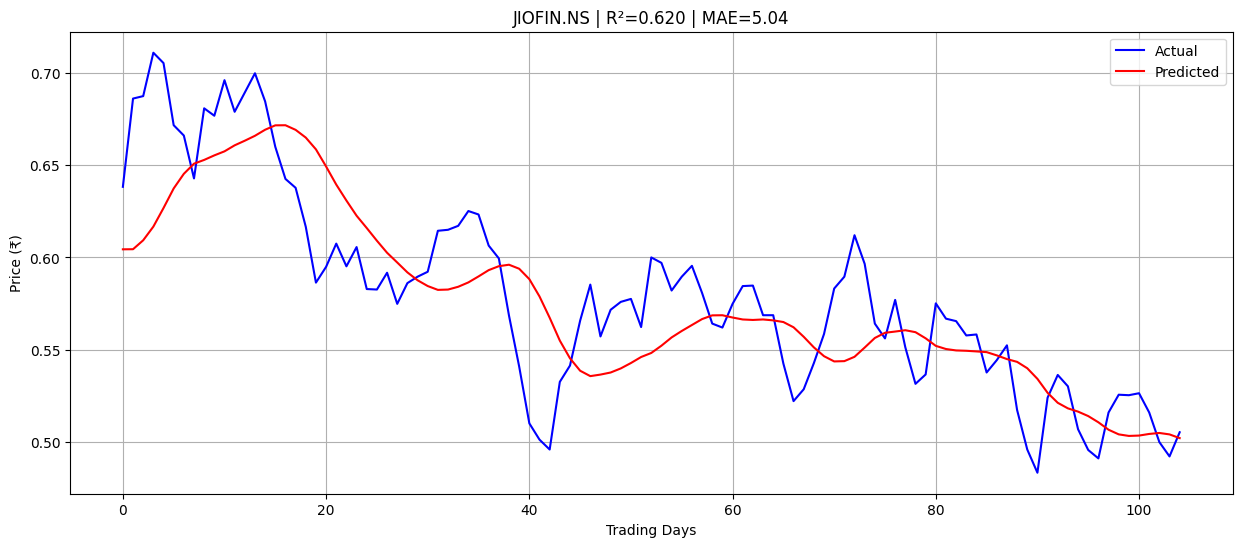

In [ ]:
for result in results:
    plot_from_results(result)